# Tarea 4 - Diplomado ML Facultad de Ingeniería

> Edgar Ulises Moreno Chalico
>
> 318192950

1. Aplica SVM a abalone.csv
Usa gridsearchCV, qué kernel es mejor en accuracy?
más detalles en: https://archive.ics.uci.edu/dataset/1/abalone

2. Aplica regresión lineal y SVR a liver.csv
Compara qué modelo es mejor
Más detalles en: https://archive.ics.uci.edu/dataset/60/liver+disorders

3. Aplica SVM a car.csv
Usa gridsearchCV, qué kernel es mejor en accuracy?
más detalles en: https://archive.ics.uci.edu/dataset/19/car+evaluation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Actividad 1

Age
old      1447
young    1407
adult    1323
Name: count, dtype: int64
Mejores parámetros: {'svc__C': 10, 'svc__coef0': 1, 'svc__degree': 3, 'svc__gamma': 'scale', 'svc__kernel': 'poly'}
Mejor accuracy (CV): 66.27%
Train accuracy: 68.87%
Test accuracy: 67.38%
=> Mejor accuracy (CV) por kernel
param_svc__kernel
poly       0.662678
rbf        0.659256
linear     0.645569
sigmoid    0.613752
Name: mean_test_score, dtype: float64
              precision    recall  f1-score   support

       adult       0.53      0.61      0.57       397
         old       0.72      0.69      0.70       435
       young       0.79      0.72      0.76       422

    accuracy                           0.67      1254
   macro avg       0.68      0.67      0.68      1254
weighted avg       0.68      0.67      0.68      1254

Número de vectores de soporte por clase: [872 658 434]


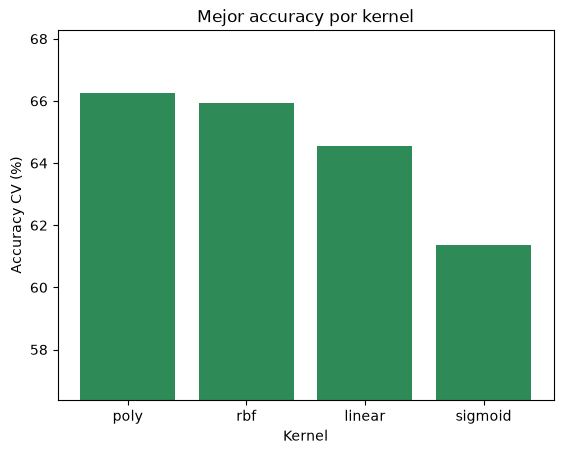

In [2]:
from sklearn.metrics import classification_report
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("./abalone.csv")

df["Age"] = pd.cut(df["Rings"], bins=[0, 8, 10, 30], labels=["young", "adult", "old"])
print(df["Age"].value_counts())

# Sex es categórica (M, F, I), se convierte a variables dummy
X = pd.get_dummies(df.drop(columns=["Rings", "Age"]), columns=["Sex"])
y = df["Age"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

pipe = Pipeline([("scaler", StandardScaler()), ("svc", SVC())])

param_grid = [
    {"svc__kernel": ["linear"], "svc__C": [0.1, 1, 10, 100]},
    {"svc__kernel": ["rbf"], "svc__C": [0.1, 1, 10, 100], "svc__gamma": ["scale", 0.01, 0.1, 1]},
    {"svc__kernel": ["poly"], "svc__C": [0.1, 1, 10], "svc__degree": [2, 3], "svc__gamma": ["scale", 0.1],
     "svc__coef0": [0, 1]},
    {"svc__kernel": ["sigmoid"], "svc__C": [0.1, 1, 10], "svc__gamma": ["scale", 0.01, 0.1], "svc__coef0": [0, 1]},
]

grid = GridSearchCV(pipe, param_grid, cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

model = grid.best_estimator_

print(f"Mejores parámetros: {grid.best_params_}")
print(f"Mejor accuracy (CV): {grid.best_score_ * 100:.2f}%")

score_train = model.score(X_train, y_train)
score_test = model.score(X_test, y_test)

print(f"Train accuracy: {score_train * 100:.2f}%")
print(f"Test accuracy: {score_test * 100:.2f}%")

# Mejor accuracy por kernel
resultados = pd.DataFrame(grid.cv_results_)
por_kernel = resultados.groupby("param_svc__kernel")["mean_test_score"].max().sort_values(ascending=False)
print("=> Mejor accuracy (CV) por kernel")
print(por_kernel)

y_pred_test = model.predict(X_test)
print(classification_report(y_test, y_pred_test))

print(f"Número de vectores de soporte por clase: {model['svc'].n_support_}")

plt.bar(por_kernel.index, por_kernel.values * 100, color="seagreen")
plt.ylim(por_kernel.min() * 100 - 5, por_kernel.max() * 100 + 2)
plt.xlabel("Kernel")
plt.ylabel("Accuracy CV (%)")
plt.title("Mejor accuracy por kernel")
plt.show()


Nota: `Rings` se agrupó en 3 clases de edad (joven ≤ 8, adulto 9–10, viejo ≥ 11), ya que con las 28 clases originales algunas tienen una sola muestra.

## Actividad 2

(345, 6)
Mejores parámetros SVR: {'regressor__svr__C': 0.1, 'regressor__svr__epsilon': 0.5, 'regressor__svr__gamma': 'scale', 'regressor__svr__kernel': 'sigmoid'}
Mejor r2 SVR (CV): 13.08%
=> Comparación (promedio de 10 folds)
                        R2       MAE      RMSE
Regresión lineal  0.060179  2.403908  3.088934
SVR               0.130829  2.287647  2.989704


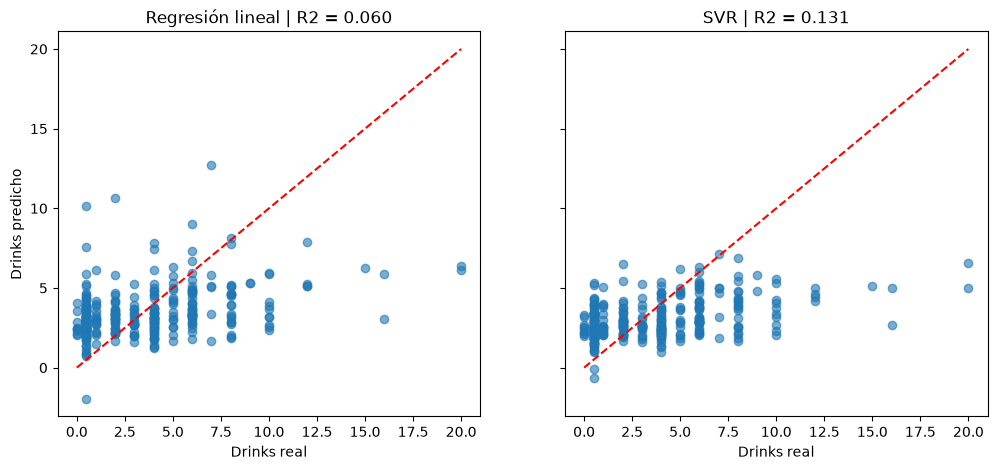

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, cross_val_predict

df = pd.read_csv("./liver.csv").iloc[:, 1:]
print(df.shape)

X = df.drop(columns=["drinks"])
y = df["drinks"]

# Mismos folds para ambos modelos
folds = KFold(n_splits=10, shuffle=True, random_state=0)

modelo_lineal = make_pipeline(StandardScaler(), LinearRegression())

modelo_svr = TransformedTargetRegressor(regressor=make_pipeline(
    StandardScaler(),
    SVR()
), transformer=StandardScaler())

parameters = {
    "regressor__svr__kernel": ["linear", "poly", "rbf", "sigmoid"],
    "regressor__svr__C": [0.01, 0.1, 1, 10, 100],
    "regressor__svr__epsilon": [0.01, 0.1, 0.5],
    "regressor__svr__gamma": ["scale", "auto"],
}

grid = GridSearchCV(modelo_svr, parameters, cv=folds, scoring="r2", n_jobs=-1)
grid.fit(X, y)

print(f"Mejores parámetros SVR: {grid.best_params_}")
print(f"Mejor r2 SVR (CV): {grid.best_score_ * 100:.2f}%")

modelos = {
    "Regresión lineal": modelo_lineal,
    "SVR": grid.best_estimator_,
}

metricas = ["r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"]
resultados = {}
predicciones = {}

for nombre, modelo in modelos.items():
    scores = cross_validate(modelo, X, y, cv=folds, scoring=metricas, n_jobs=-1)
    resultados[nombre] = {
        "R2": scores["test_r2"].mean(),
        "MAE": -scores["test_neg_mean_absolute_error"].mean(),
        "RMSE": -scores["test_neg_root_mean_squared_error"].mean(),
    }
    predicciones[nombre] = cross_val_predict(modelo, X, y, cv=folds, n_jobs=-1)

comparacion = pd.DataFrame(resultados).T
print("=> Comparación (promedio de 10 folds)")
print(comparacion)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
limits = [y.min(), y.max()]

for ax, (nombre, y_pred) in zip(axes, predicciones.items()):
    ax.scatter(y, y_pred, alpha=0.6)
    ax.plot(limits, limits, "r--")
    ax.set_title(f"{nombre} | R2 = {resultados[nombre]['R2']:.3f}")
    ax.set_xlabel("Drinks real")

axes[0].set_ylabel("Drinks predicho")
plt.show()


**SVR es mejor** en las tres métricas: duplica el R² y reduce el error. Aun así, ambos modelos explican muy poco de la variable `drinks` (R² bajo), porque los análisis de sangre por sí solos predicen mal la cantidad de bebidas consumidas. El R² del SVR es algo optimista, ya que sus hiperparámetros se eligieron con los mismos folds.

## Actividad 3

(1728, 7)
Class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64
Mejores parámetros: {'svm__C': 10, 'svm__coef0': 0, 'svm__degree': 3, 'svm__gamma': 'scale', 'svm__kernel': 'poly'}
Mejor accuracy (CV): 99.59%
Train accuracy: 100.00%
Test accuracy: 99.42%
=> Mejor accuracy (CV) por kernel
param_svm__kernel
poly       0.995857
rbf        0.995031
linear     0.945407
sigmoid    0.925558
Name: mean_test_score, dtype: float64
              precision    recall  f1-score   support

         acc       0.98      1.00      0.99       115
        good       0.95      0.95      0.95        21
       unacc       1.00      1.00      1.00       363
       vgood       1.00      0.95      0.97        20

    accuracy                           0.99       519
   macro avg       0.98      0.97      0.98       519
weighted avg       0.99      0.99      0.99       519



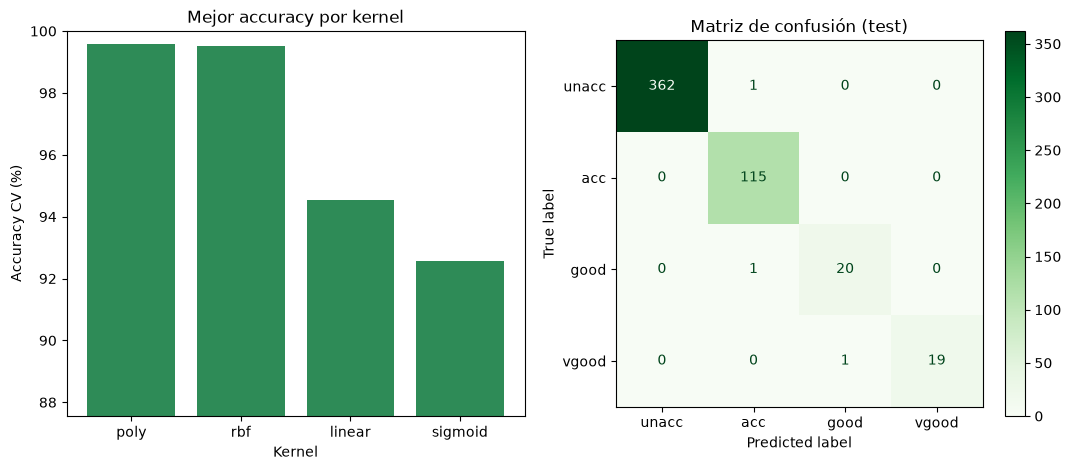

In [4]:
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

df = pd.read_csv("./car.csv").iloc[:, 1:]
print(df.shape)
print(df["Class"].value_counts())

X = df.drop(columns=["Class"]).astype(str)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

# Todas las variables son categóricas
processor = ColumnTransformer([
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), X.columns.tolist()),
])

model = Pipeline([
    ("preprocessing", processor),
    ("svm", SVC())
])

parameters = [
    {"svm__kernel": ["linear"], "svm__C": [0.01, 0.1, 1, 10, 100]},
    {"svm__kernel": ["poly"], "svm__C": [0.1, 1, 10, 100], "svm__degree": [2, 3], "svm__gamma": ["scale", "auto"],
     "svm__coef0": [0, 1]},
    {"svm__kernel": ["rbf"], "svm__C": [0.1, 1, 10, 100], "svm__gamma": ["scale", 0.01, 0.1, 1]},
    {"svm__kernel": ["sigmoid"], "svm__C": [0.1, 1, 10, 100], "svm__gamma": ["scale", 0.01, 0.1], "svm__coef0": [0, 1]},
]

grid = GridSearchCV(model, parameters, cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

final_model = grid.best_estimator_

print(f"Mejores parámetros: {grid.best_params_}")
print(f"Mejor accuracy (CV): {grid.best_score_ * 100:.2f}%")

score_train = final_model.score(X_train, y_train)
score_test = final_model.score(X_test, y_test)

print(f"Train accuracy: {score_train * 100:.2f}%")
print(f"Test accuracy: {score_test * 100:.2f}%")

# Mejor accuracy por kernel
resultados = pd.DataFrame(grid.cv_results_)
por_kernel = resultados.groupby("param_svm__kernel")["mean_test_score"].max().sort_values(ascending=False)
print("=> Mejor accuracy (CV) por kernel")
print(por_kernel)

y_pred_test = final_model.predict(X_test)
print(classification_report(y_test, y_pred_test))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(por_kernel.index, por_kernel.values * 100, color="seagreen")
axes[0].set_ylim(por_kernel.min() * 100 - 5, 100)
axes[0].set_xlabel("Kernel")
axes[0].set_ylabel("Accuracy CV (%)")
axes[0].set_title("Mejor accuracy por kernel")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, labels=["unacc", "acc", "good", "vgood"], ax=axes[1],
                                        cmap="Greens")
axes[1].set_title("Matriz de confusión (test)")

plt.show()


Con GridSearchCV (5 folds) el mejor kernel en accuracy es **poly** con ~99.6% en validación cruzada y ~99.4% en prueba, muy cerca de rbf (~99.5%) y por encima de linear (~94.5%) y sigmoid (~92.6%).

Las clases están desbalanceadas (unacc domina), pero el reporte de clasificación muestra que también las clases minoritarias (good, vgood) se predicen bien (f1 ≥ 0.95).